# Name : Md. Masudul Hasan Akib
## Email : akibhasan011@gmail.com

In [ ]:
print('In the name of Allah')

In the name of Allah


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder, StandardScaler, MinMaxScaler, RobustScaler

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, SGDRegressor, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, accuracy_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import GridSearchCV

# Question 1: Exploratory Data Analysis (EDA) -20

In [ ]:
df = pd.read_csv('adult_income.csv')

df.head(5)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
df.shape

(48842, 15)

In [ ]:
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


In [ ]:
df.duplicated().sum()

np.int64(29)

In [ ]:
df.drop_duplicates(inplace = True)
df.shape

(48813, 15)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48813 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48813 non-null  int64 
 1   workclass       48813 non-null  object
 2   fnlwgt          48813 non-null  int64 
 3   education       48813 non-null  object
 4   education-num   48813 non-null  int64 
 5   marital-status  48813 non-null  object
 6   occupation      48813 non-null  object
 7   relationship    48813 non-null  object
 8   race            48813 non-null  object
 9   sex             48813 non-null  object
 10  capital-gain    48813 non-null  int64 
 11  capital-loss    48813 non-null  int64 
 12  hours-per-week  48813 non-null  int64 
 13  native-country  48813 non-null  object
 14  income          48813 non-null  object
dtypes: int64(6), object(9)
memory usage: 6.0+ MB


In [ ]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48813.000000,4.881300e+04,48813.000000,48813.000000,48813.000000,48813.000000
mean,38.647348,1.896679e+05,10.078688,1079.708705,87.554299,40.425051
std,13.709005,1.056062e+05,2.570257,7454.185982,403.118605,12.390954
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175550e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781400e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376200e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [ ]:
df['income'].value_counts()

,count
income,
<=50K,24698
<=50K.,12430
>50K,7839
>50K.,3846


In [ ]:
df['income'] = df['income'].replace({
    ' <=50K.' : ' <=50K',
    ' >50K.' : ' >50K'
})

In [ ]:
df['income'].value_counts()

,count
income,
<=50K,37128
>50K,11685


In [ ]:
df['income'].unique()

array([' <=50K', ' >50K'], dtype=object)

In [ ]:
df['income'] = df['income'].replace({
    ' <=50K' : '<=50K',
    ' >50K' : '>50K'
})

df['income'].unique()

array(['<=50K', '>50K'], dtype=object)

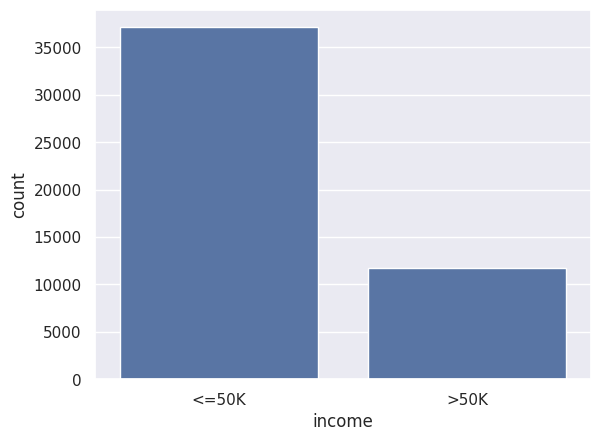

In [ ]:
sns.countplot(data = df, x = 'income')
plt.show()

In [ ]:
df['education'].value_counts()

,count
education,
HS-grad,15777
Some-college,10869
Bachelors,8020
Masters,2656
Assoc-voc,2060
11th,1812
Assoc-acdm,1601
10th,1389
7th-8th,954


In [ ]:
df.info()  # age, education, marital-status, relationship, sex, occupation, hours-per-week

<class 'pandas.core.frame.DataFrame'>
Index: 48813 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48813 non-null  int64 
 1   workclass       48813 non-null  object
 2   fnlwgt          48813 non-null  int64 
 3   education       48813 non-null  object
 4   education-num   48813 non-null  int64 
 5   marital-status  48813 non-null  object
 6   occupation      48813 non-null  object
 7   relationship    48813 non-null  object
 8   race            48813 non-null  object
 9   sex             48813 non-null  object
 10  capital-gain    48813 non-null  int64 
 11  capital-loss    48813 non-null  int64 
 12  hours-per-week  48813 non-null  int64 
 13  native-country  48813 non-null  object
 14  income          48813 non-null  object
dtypes: int64(6), object(9)
memory usage: 6.0+ MB


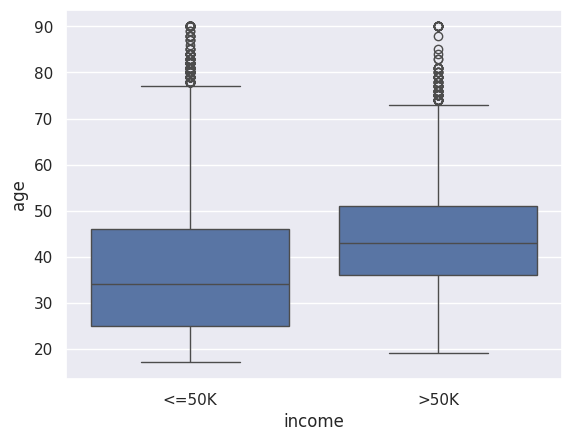

In [ ]:
sns.boxplot(data = df, x = 'income', y = 'age')

plt.show()

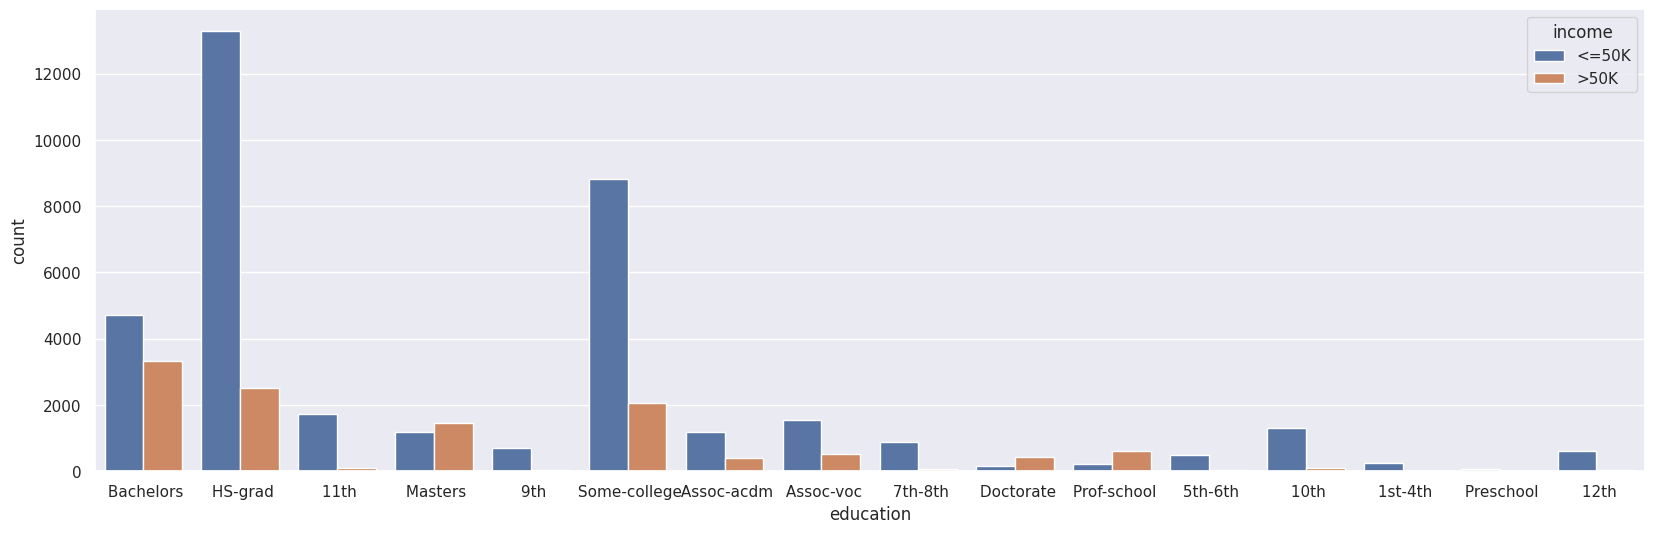

In [ ]:
plt.figure(figsize = (20, 6))

sns.countplot(data = df, x = 'education', hue = 'income')

plt.show()

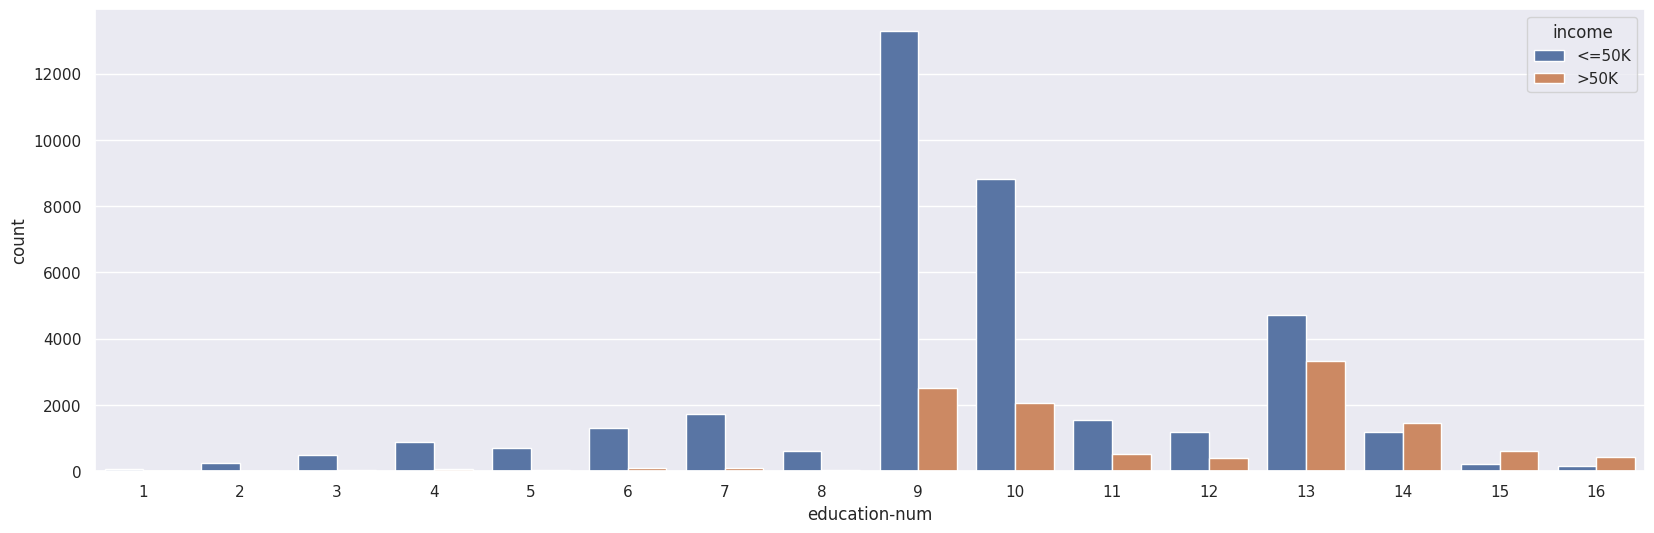

In [ ]:
plt.figure(figsize = (20, 6))

sns.countplot(data = df, x = 'education-num', hue = 'income')

plt.show()

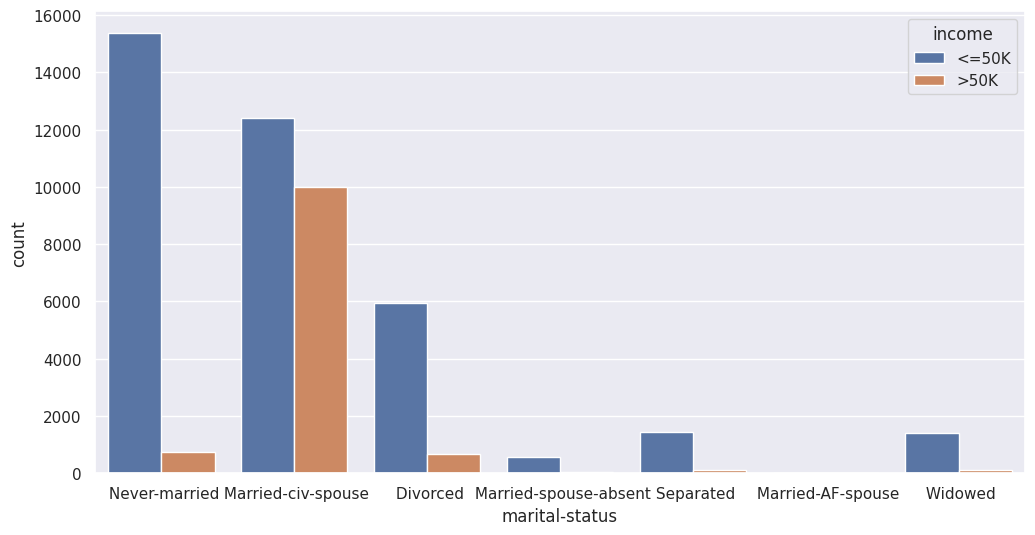

In [ ]:
plt.figure(figsize = (12, 6))

sns.countplot( data = df, x = 'marital-status', hue = 'income' )
plt.show()

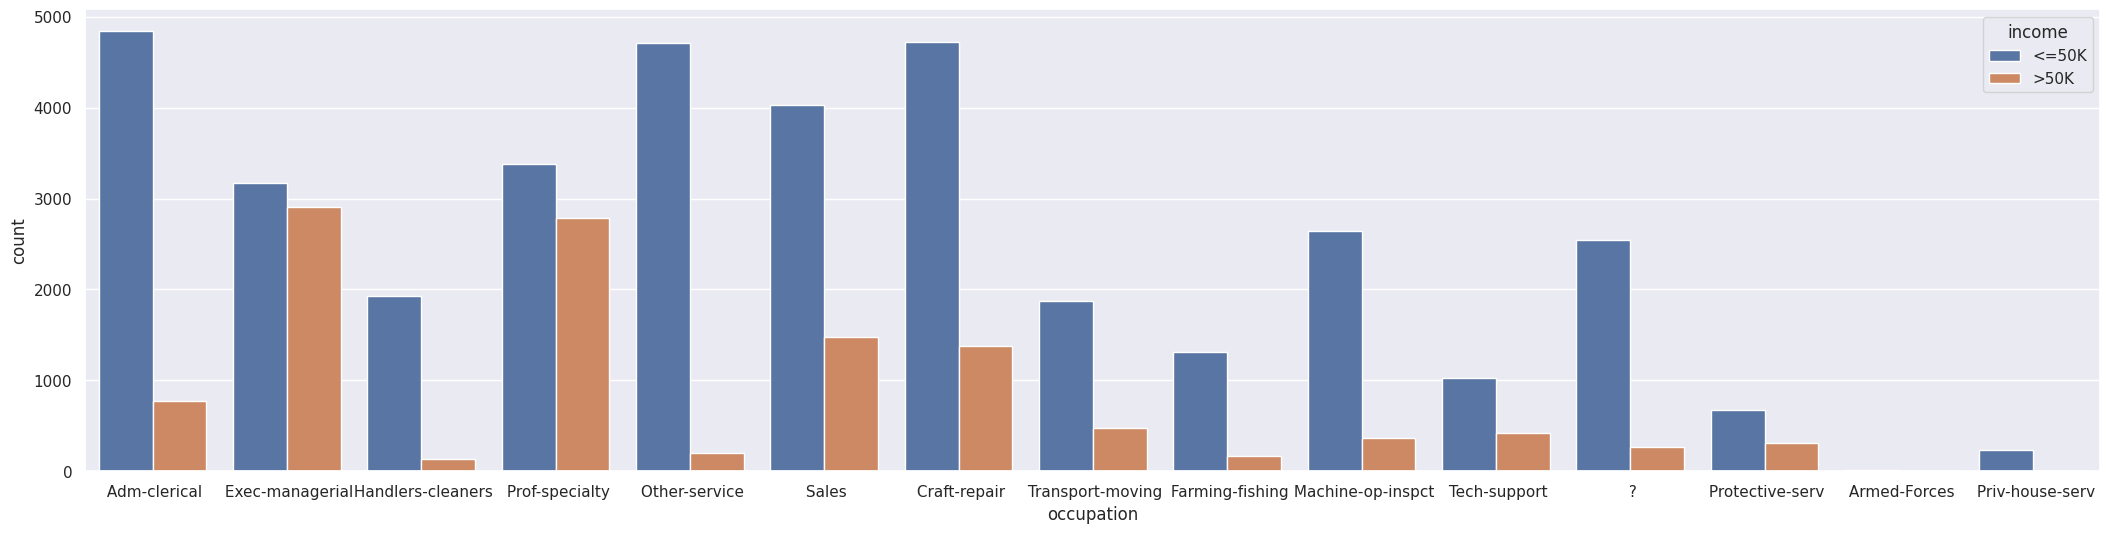

In [ ]:
plt.figure(figsize = (26, 6))

sns.countplot( data = df, x = 'occupation', hue = 'income' )

plt.show()

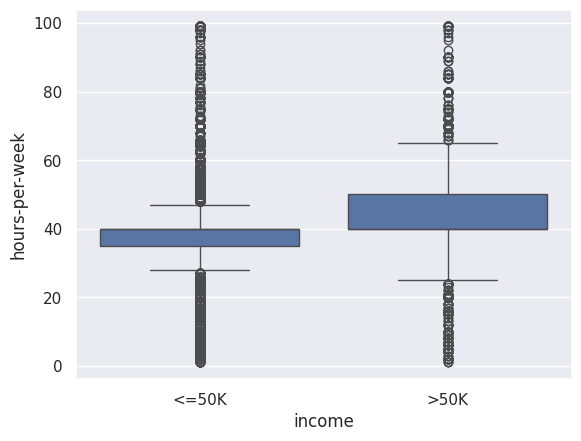

In [ ]:
sns.boxplot(data = df, x = 'income', y = 'hours-per-week')

plt.show()

In [ ]:
df['fnlwgt'].nunique()

28523

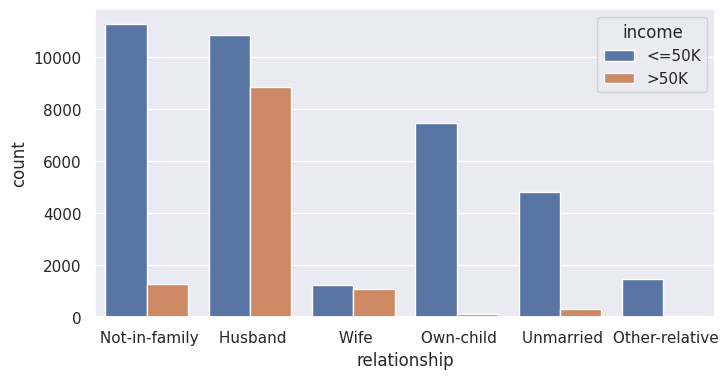

In [ ]:
plt.figure(figsize = (8, 4))

sns.countplot(data = df, x = 'relationship', hue = 'income')

plt.show()

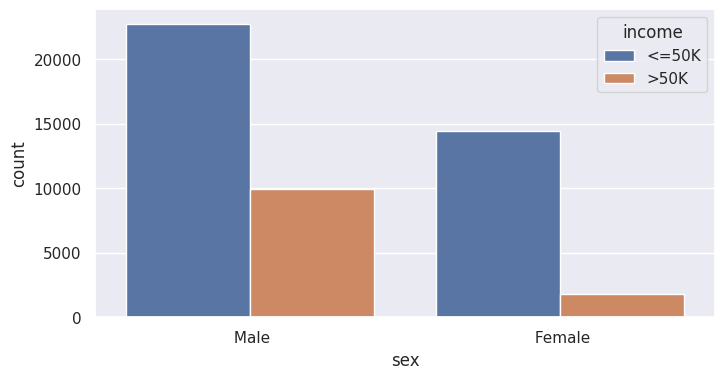

In [ ]:
plt.figure(figsize = (8, 4))

sns.countplot(data = df, x = 'sex', hue = 'income')

plt.show()

In [ ]:
df['relationship'].unique()

array([' Not-in-family', ' Husband', ' Wife', ' Own-child', ' Unmarried',
       ' Other-relative'], dtype=object)

In [ ]:
df['capital-gain'].unique()

array([ 2174,     0, 14084,  5178,  5013,  2407, 14344, 15024,  7688,
       34095,  4064,  4386,  7298,  1409,  3674,  1055,  3464,  2050,
        2176,   594, 20051,  6849,  4101,  1111,  8614,  3411,  2597,
       25236,  4650,  9386,  2463,  3103, 10605,  2964,  3325,  2580,
        3471,  4865, 99999,  6514,  1471,  2329,  2105,  2885, 25124,
       10520,  2202,  2961, 27828,  6767,  2228,  1506, 13550,  2635,
        5556,  4787,  3781,  3137,  3818,  3942,   914,   401,  2829,
        2977,  4934,  2062,  2354,  5455, 15020,  1424,  3273, 22040,
        4416,  3908, 10566,   991,  4931,  1086,  7430,  6497,   114,
        7896,  2346,  3418,  3432,  2907,  1151,  2414,  2290, 15831,
       41310,  4508,  2538,  3456,  6418,  1848,  3887,  5721,  9562,
        1455,  2036,  1831, 11678,  2936,  2993,  7443,  6360,  1797,
        1173,  4687,  6723,  2009,  6097,  2653,  1639, 18481,  7978,
        2387,  5060,  1264,  7262,  1731,  6612])

In [ ]:
df['capital-loss'].unique()

array([   0, 2042, 1408, 1902, 1573, 1887, 1719, 1762, 1564, 2179, 1816,
       1980, 1977, 1876, 1340, 2206, 1741, 1485, 2339, 2415, 1380, 1721,
       2051, 2377, 1669, 2352, 1672,  653, 2392, 1504, 2001, 1590, 1651,
       1628, 1848, 1740, 2002, 1579, 2258, 1602,  419, 2547, 2174, 2205,
       1726, 2444, 1138, 2238,  625,  213, 1539,  880, 1668, 1092, 1594,
       3004, 2231, 1844,  810, 2824, 2559, 2057, 1974,  974, 2149, 1825,
       1735, 1258, 2129, 2603, 2282,  323, 4356, 2246, 1617, 1648, 2489,
       3770, 1755, 3683, 2267, 2080, 2457,  155, 3900, 2201, 1944, 2467,
       2163, 2754, 2472, 1411, 1429, 3175, 1510, 1870, 1911, 2465, 1421])

In [ ]:
# occupation, marital-status, sex

After performing Exploratory Data Analysis (EDA), I selected Occupation, sex, and Marital-status as the three most important features that help separate individuals earning more than 50K and those earning 50K or less.

Among these feature Occupation is the most important. From the visualization, people who do better job, have higher salary. Occupation directly affects income because different jobs have different salary ranges. Thats why i ranked occupation as the most important feature.

The second most important feature is Marital-status. The visualization shows a massive income gap based on relationship status.

Finally, Sex serves as the third key feature. From the sex and income visualization, we can observe that male individuals have a higher rate of earning above 50K compared to female individuals.

# Question 2: Preprocessing Pipeline Design (Regression) - 20


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48813 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48813 non-null  int64 
 1   workclass       48813 non-null  object
 2   fnlwgt          48813 non-null  int64 
 3   education       48813 non-null  object
 4   education-num   48813 non-null  int64 
 5   marital-status  48813 non-null  object
 6   occupation      48813 non-null  object
 7   relationship    48813 non-null  object
 8   race            48813 non-null  object
 9   sex             48813 non-null  object
 10  capital-gain    48813 non-null  int64 
 11  capital-loss    48813 non-null  int64 
 12  hours-per-week  48813 non-null  int64 
 13  native-country  48813 non-null  object
 14  income          48813 non-null  object
dtypes: int64(6), object(9)
memory usage: 6.0+ MB


In [ ]:
df['occupation'].unique()

array([' Adm-clerical', ' Exec-managerial', ' Handlers-cleaners',
       ' Prof-specialty', ' Other-service', ' Sales', ' Craft-repair',
       ' Transport-moving', ' Farming-fishing', ' Machine-op-inspct',
       ' Tech-support', ' ?', ' Protective-serv', ' Armed-Forces',
       ' Priv-house-serv'], dtype=object)

In [ ]:
( df == ' ?' ).sum()

,0
age,0
workclass,2799
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,2809
relationship,0
race,0
sex,0


In [ ]:
df = df.replace(' ?', np.nan)

df.isnull().sum()

,0
age,0
workclass,2799
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,2809
relationship,0
race,0
sex,0


In [ ]:
X = df.drop( ['fnlwgt', 'education-num', 'hours-per-week'] , axis = 1)
y = df['hours-per-week']

In [ ]:
X['income'].unique()

le = LabelEncoder()

X['income'] = le.fit_transform(X['income'])

X['income'].unique()

array([0, 1])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((39050, 12), (9763, 12), (39050,), (9763,))

In [ ]:
numeric_feature = X_train.select_dtypes(
    include = ['int64', 'float64']
).columns

numeric_feature

Index(['age', 'capital-gain', 'capital-loss', 'income'], dtype='object')

In [ ]:
categorical_feature = X_train.select_dtypes(
    include = ['object']
).columns

categorical_feature

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')

In [ ]:
X_train[numeric_feature].describe()

,age,capital-gain,capital-loss,income
count,39050.000000,39050.000000,39050.000000,39050.000000
mean,38.618105,1064.588988,88.494289,0.238079
std,13.719349,7381.468694,405.143746,0.425913
min,17.000000,0.000000,0.000000,0.000000
25%,28.000000,0.000000,0.000000,0.000000
50%,37.000000,0.000000,0.000000,0.000000
75%,48.000000,0.000000,0.000000,0.000000
max,90.000000,99999.000000,4356.000000,1.000000


In [ ]:
x = 5
x = x / 100

Q1 = X_train['capital-gain'].quantile(x)
Q3 = X_train['capital-gain'].quantile(1 - x)

IQR = Q3 - Q1

lower = max(0, Q1 - 1.5 * IQR)
upper = Q3 + 1.5 * IQR

outlier_IQR = X_train[(X_train['capital-gain'] < lower) | (X_train['capital-gain'] > upper)]

print(len(outlier_IQR))
print(f'Max : {X_train['capital-gain'].max()}, Min : {X_train['capital-gain'].min()}')

X_train['capital-gain'] = X_train['capital-gain'].clip(lower, upper)

print(f'Max : {X_train['capital-gain'].max()}, Min : {X_train['capital-gain'].min()}')


831
Max : 99999, Min : 0
Max : 12162.5, Min : 0.0


In [ ]:
X_train[numeric_feature].skew()

,0
age,0.553686
capital-gain,4.247049
capital-loss,4.528281
income,1.229987


In [ ]:
X_train['education'].unique()

array([' Prof-school', ' 12th', ' Bachelors', ' Some-college', ' HS-grad',
       ' Doctorate', ' Assoc-acdm', ' Assoc-voc', ' Masters', ' 11th',
       ' 7th-8th', ' 10th', ' 9th', ' 5th-6th', ' 1st-4th', ' Preschool'],
      dtype=object)

In [ ]:
categorical_transformer = Pipeline(
    steps = [
        ('imputer', SimpleImputer(strategy = 'most_frequent')),
        ('encoder', OneHotEncoder(sparse_output = False,drop = 'first', handle_unknown = 'ignore'))
    ]
)

categorical_transformer

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder',
                 OneHotEncoder(drop='first', handle_unknown='ignore',
                               sparse_output=False))])

In [ ]:
num_transformer = Pipeline(
    steps = [
        ('imputer', SimpleImputer(strategy = 'median')),
        ('scaler', StandardScaler())
    ]
)

num_transformer

age_transformer = Pipeline(
    steps = [
        ('imputer', SimpleImputer(strategy = 'mean')),
        ('scaler', StandardScaler())
    ]
)

age_transformer, num_transformer

(Pipeline(steps=[('imputer', SimpleImputer()), ('scaler', StandardScaler())]),
 Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                 ('scaler', StandardScaler())]))

In [ ]:
education_order = [
    ' Preschool', ' 1st-4th', ' 5th-6th', ' 7th-8th', ' 9th',' 10th', ' 11th', ' 12th',
    ' HS-grad', ' Some-college',' Assoc-voc', ' Assoc-acdm', ' Bachelors', ' Prof-school',
    ' Masters', ' Doctorate'
]

missing = ['workclass', 'occupation', 'native-country']
cat = ['workclass', 'occupation', 'native-country', 'marital-status', 'relationship', 'race', 'sex']

preprocessor = ColumnTransformer(
    transformers = [
        ( 'edu', OrdinalEncoder( categories = [education_order] ), ['education'] ),
        ( 'cat', categorical_transformer, cat ),
        ( 'age', age_transformer, ['age'] ),
        ( 'numeric', num_transformer, [ 'capital-gain', 'capital-loss' ] )
    ],
    remainder = 'passthrough',
    verbose_feature_names_out = False
)

preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('edu',
                                 OrdinalEncoder(categories=[[' Preschool',
                                                             ' 1st-4th',
                                                             ' 5th-6th',
                                                             ' 7th-8th', ' 9th',
                                                             ' 10th', ' 11th',
                                                             ' 12th',
                                                             ' HS-grad',
                                                             ' Some-college',
                                                             ' Assoc-voc',
                                                             ' Assoc-acdm',
                                                             ' Bachelors',
                                                             ' Prof-school',
                                                             ' Masters',
                                                             ' Doctorate']]),
                                 ['education']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent'))...
                                                                sparse_output=False))]),
                                 ['workclass', 'occupation', 'native-country',
                                  'marital-status', 'relationship', 'race',
                                  'sex']),
                                ('age',
                                 Pipeline(steps=[('imputer', SimpleImputer()),
                                                 ('scaler', StandardScaler())]),
                                 ['age']),
                                ('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['capital-gain', 'capital-loss'])],
                  verbose_feature_names_out=False)

I removed fnlwgt because it is not predictive, education-num because it duplicates the information in education, and income because it is the target variable.

The dataset uses ' ?' to represent missing values, so I replaced them with NaN and handled them using SimpleImputer most frequent for categorical features.

I used Ordinal Encoding for the education column because education levels have a natural order. For the remaining categorical features, I applied One-Hot Encoding to convert them into numerical form while handling unseen categories.

For numerical features, I clipped extreme values in capital-gain using the IQR method to reduce the impact of outliers. Then, I applied StandardScaler to all numerical features so that they have a similar scale, which helps machine learning models perform better.


# Question 3: Regression Modeling & Evaluation - 20

In [ ]:
lr_pipeline = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]
)

lr_pipeline.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('edu',
                                                  OrdinalEncoder(categories=[[' '
                                                                              'Preschool',
                                                                              ' '
                                                                              '1st-4th',
                                                                              ' '
                                                                              '5th-6th',
                                                                              ' '
                                                                              '7th-8th',
                                                                              ' '
                                                                              '9th',
                                                                              ' '
                                                                              '10th',
                                                                              ' '
                                                                              '11th',
                                                                              ' '
                                                                              '12th',
                                                                              ' '
                                                                              'HS-grad',
                                                                              ' '
                                                                              'Some-college',
                                                                              ' '
                                                                              'Assoc-voc',
                                                                              ' '
                                                                              'Assoc-acdm',
                                                                              ' '
                                                                              'Bachelors',
                                                                              ' '
                                                                              'Prof-school',
                                                                              ' '
                                                                              'Masters',
                                                                              ' '
                                                                              'Doctorate']]),
                                                  ['education']),
                                                 ('cat',
                                                  Pip...
                                                   'native-country',
                                                   'marital-status',
                                                   'relationship', 'race',
                                                   'sex']),
                                                 ('age',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age']),
                                                 ('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   

In [ ]:
lr_pipeline.predict(X_train)

array([40.21057019, 48.09707927, 43.73502149, ..., 53.54340069,
       30.52803967, 43.28405382])

In [ ]:
ETA = 0.00001
MAX_ITER = 10000
ALPHA = 0.01


sgd_pipeline = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('model', SGDRegressor(
            loss = 'squared_error',
            penalty = 'l2',
            alpha = ALPHA,
            learning_rate = 'constant',
            eta0 = ETA,
            max_iter = MAX_ITER,
            random_state = 42

        ))
    ]
)

sgd_pipeline.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('edu',
                                                  OrdinalEncoder(categories=[[' '
                                                                              'Preschool',
                                                                              ' '
                                                                              '1st-4th',
                                                                              ' '
                                                                              '5th-6th',
                                                                              ' '
                                                                              '7th-8th',
                                                                              ' '
                                                                              '9th',
                                                                              ' '
                                                                              '10th',
                                                                              ' '
                                                                              '11th',
                                                                              ' '
                                                                              '12th',
                                                                              ' '
                                                                              'HS-grad',
                                                                              ' '
                                                                              'Some-college',
                                                                              ' '
                                                                              'Assoc-voc',
                                                                              ' '
                                                                              'Assoc-acdm',
                                                                              ' '
                                                                              'Bachelors',
                                                                              ' '
                                                                              'Prof-school',
                                                                              ' '
                                                                              'Masters',
                                                                              ' '
                                                                              'Doctorate']]),
                                                  ['education']),
                                                 ('cat',
                                                  Pip...
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age']),
                                                 ('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['capital-gain',
                                                   'capital-los

In [ ]:
# Evaluation

def evaluate(model, name) :
  train_pred = model.predict(X_train)
  test_pred = model.predict(X_test)

  print(f'\n{name}')
  print("-"*40)

  print('Train r2 : ', round(r2_score(y_train, train_pred), 4))
  print('Test r2  : ',round(r2_score(y_test, test_pred), 4))

  print('MAE      : ',round(mean_absolute_error(y_test, test_pred),4))

  print('MSE      : ',round((mean_squared_error(y_test, test_pred)),4))


  return(
      r2_score(y_test, test_pred),
      mean_squared_error(y_test, test_pred),
      mean_absolute_error(y_test, test_pred)
  )

In [ ]:
lr_r2, lr_mse, lr_mae = evaluate(
    lr_pipeline,
    'Linear Regression'
)



Linear Regression
----------------------------------------
Train r2 :  0.1883
Test r2  :  0.1768
MAE      :  7.781
MSE      :  125.7325


/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [ ]:
sgd_r2, sgd_mse, sgd_mae = evaluate(
    sgd_pipeline,
    'SGD Regression'
)


SGD Regression
----------------------------------------
Train r2 :  0.1821
Test r2  :  0.1734
MAE      :  7.7623
MSE      :  126.242


/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [ ]:
comparison = pd.DataFrame({
      "R2 Score": [lr_r2, sgd_r2],
      "MAE" : [lr_mae, sgd_mae],
      "MSE": [lr_mse, sgd_mse]
    },
    index=["Linear Regression", "SGD Regressor"]
)

print(comparison)

                   R2 Score       MAE         MSE
Linear Regression  0.176752  7.781012  125.732549
SGD Regressor      0.173416  7.762284  126.241971


Linear Regression is perform better. Linear Regression achive higher R2 score than SGD Regressor. That means it explained more variance in the target variable. Also it hase lower MAE and MSE, which indicates its predications were slightly more accurate.

# Question 4: Classification Pipeline & Error Analysis -20


In [ ]:
df.isnull().sum()

,0
age,0
workclass,2799
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,2809
relationship,0
race,0
sex,0


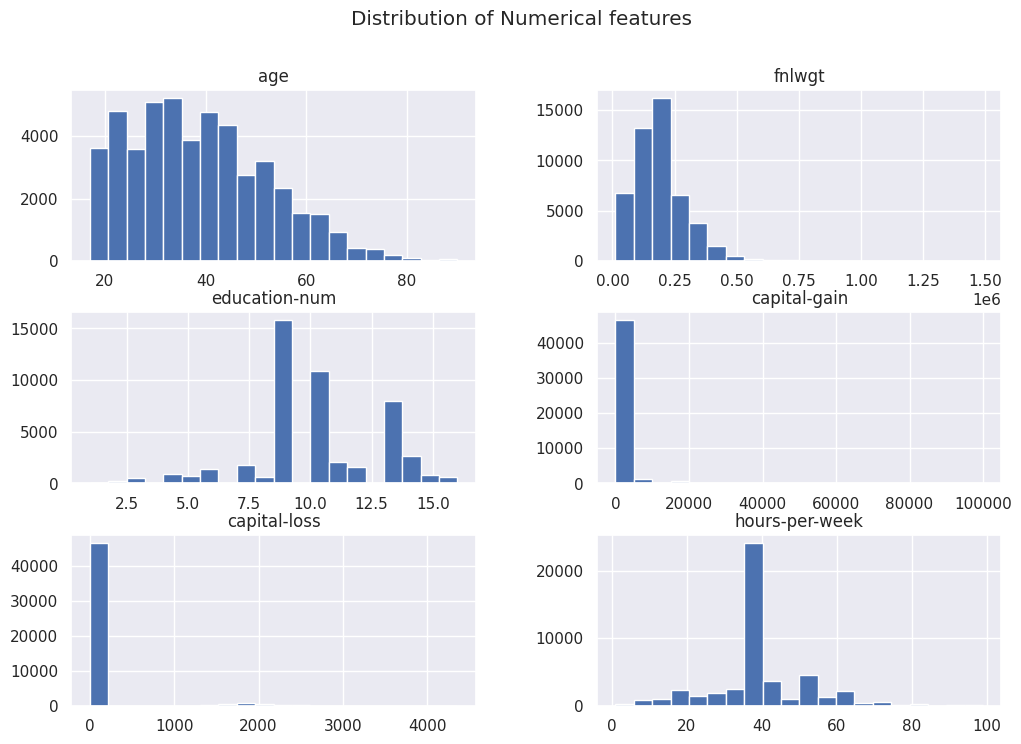

In [ ]:
df.hist(figsize = (12, 8), bins = 20)

plt.suptitle('Distribution of Numerical features')
plt.show()

In [ ]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48813.000000,4.881300e+04,48813.000000,48813.000000,48813.000000,48813.000000
mean,38.647348,1.896679e+05,10.078688,1079.708705,87.554299,40.425051
std,13.709005,1.056062e+05,2.570257,7454.185982,403.118605,12.390954
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175550e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781400e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376200e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [ ]:
df[['age', 'capital-gain', 'capital-loss', 'hours-per-week']].skew()

,0
age,0.556775
capital-gain,11.891093
capital-loss,4.568263
hours-per-week,0.239643


In [ ]:
X = df.drop( ['fnlwgt', 'education-num', 'income'], axis = 1 )
y = df['income']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2, random_state = 42, stratify = y )

In [ ]:
x = 5
x = x / 100

Q1 = X_train['capital-gain'].quantile(x)
Q3 = X_train['capital-gain'].quantile(1 - x)

IQR = Q3 - Q1

lower = max(0, Q1 - 1.5 * IQR)
upper = Q3 + 1.5 * IQR

outlier_IQR = X_train[(X_train['capital-gain'] < lower) | (X_train['capital-gain'] > upper)]

print(len(outlier_IQR))
print(f'Max : {X_train['capital-gain'].max()}, Min : {X_train['capital-gain'].min()}')

X_train['capital-gain'] = X_train['capital-gain'].clip(lower, upper)

print(f'Max : {X_train['capital-gain'].max()}, Min : {X_train['capital-gain'].min()}')


806
Max : 99999, Min : 0
Max : 12532.5, Min : 0.0


In [ ]:
numeric_feature = X_train.select_dtypes(
    include = ['int64', 'float64']
).columns

numeric_feature

Index(['age', 'capital-gain', 'capital-loss', 'hours-per-week'], dtype='object')

In [ ]:
categorical_feature = X_train.select_dtypes(
    include = ['object']
).columns

categorical_feature

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')

In [ ]:
categorical_transformer = Pipeline(
    steps = [
        ('imputer', SimpleImputer(strategy = 'most_frequent')),
        ('encoder', OneHotEncoder(sparse_output = False,drop = 'first', handle_unknown = 'ignore'))
    ]
)

categorical_transformer

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder',
                 OneHotEncoder(drop='first', handle_unknown='ignore',
                               sparse_output=False))])

In [ ]:
num_transformer = Pipeline(
    steps = [
        ('imputer', SimpleImputer(strategy = 'median')),
        ('scaler', StandardScaler())
    ]
)

num_transformer

age_transformer = Pipeline(
    steps = [
        ('imputer', SimpleImputer(strategy = 'mean')),
        ('scaler', StandardScaler())
    ]
)

age_transformer, num_transformer

(Pipeline(steps=[('imputer', SimpleImputer()), ('scaler', StandardScaler())]),
 Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                 ('scaler', StandardScaler())]))

In [ ]:
education_order = [
    ' Preschool', ' 1st-4th', ' 5th-6th', ' 7th-8th', ' 9th',' 10th', ' 11th', ' 12th',
    ' HS-grad', ' Some-college',' Assoc-voc', ' Assoc-acdm', ' Bachelors', ' Prof-school',
    ' Masters', ' Doctorate'
]

missing = ['workclass', 'occupation', 'native-country']
cat = ['workclass', 'occupation', 'native-country', 'marital-status', 'relationship', 'race', 'sex']

preprocessor = ColumnTransformer(
    transformers = [
        ( 'edu', OrdinalEncoder( categories = [education_order] ), ['education'] ),
        ( 'cat', categorical_transformer, cat ),
        ( 'age', age_transformer, ['age'] ),
        ( 'numeric', num_transformer, [ 'capital-gain', 'capital-loss', 'hours-per-week' ] )
    ],
    remainder = 'passthrough',
    verbose_feature_names_out = False
)

preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('edu',
                                 OrdinalEncoder(categories=[[' Preschool',
                                                             ' 1st-4th',
                                                             ' 5th-6th',
                                                             ' 7th-8th', ' 9th',
                                                             ' 10th', ' 11th',
                                                             ' 12th',
                                                             ' HS-grad',
                                                             ' Some-college',
                                                             ' Assoc-voc',
                                                             ' Assoc-acdm',
                                                             ' Bachelors',
                                                             ' Prof-school',
                                                             ' Masters',
                                                             ' Doctorate']]),
                                 ['education']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent'))...
                                 ['workclass', 'occupation', 'native-country',
                                  'marital-status', 'relationship', 'race',
                                  'sex']),
                                ('age',
                                 Pipeline(steps=[('imputer', SimpleImputer()),
                                                 ('scaler', StandardScaler())]),
                                 ['age']),
                                ('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['capital-gain', 'capital-loss',
                                  'hours-per-week'])],
                  verbose_feature_names_out=False)

In [ ]:
le = LabelEncoder()

le.fit(y_train)

y_train = le.transform( y_train )
y_test = le.transform( y_test )

print(y_train)

[0 0 1 ... 0 1 0]


In [ ]:
lr_model = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(class_weight = 'balanced', max_iter = 1000))
    ]
)

lr_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('edu',
                                                  OrdinalEncoder(categories=[[' '
                                                                              'Preschool',
                                                                              ' '
                                                                              '1st-4th',
                                                                              ' '
                                                                              '5th-6th',
                                                                              ' '
                                                                              '7th-8th',
                                                                              ' '
                                                                              '9th',
                                                                              ' '
                                                                              '10th',
                                                                              ' '
                                                                              '11th',
                                                                              ' '
                                                                              '12th',
                                                                              ' '
                                                                              'HS-grad',
                                                                              ' '
                                                                              'Some-college',
                                                                              ' '
                                                                              'Assoc-voc',
                                                                              ' '
                                                                              'Assoc-acdm',
                                                                              ' '
                                                                              'Bachelors',
                                                                              ' '
                                                                              'Prof-school',
                                                                              ' '
                                                                              'Masters',
                                                                              ' '
                                                                              'Doctorate']]),
                                                  ['education']),
                                                 ('cat',
                                                  Pip...
                                                   'sex']),
                                                 ('age',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age']),
                                                 ('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
             

In [ ]:
lr_model.fit( X_train, y_train )

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('edu',
                                                  OrdinalEncoder(categories=[[' '
                                                                              'Preschool',
                                                                              ' '
                                                                              '1st-4th',
                                                                              ' '
                                                                              '5th-6th',
                                                                              ' '
                                                                              '7th-8th',
                                                                              ' '
                                                                              '9th',
                                                                              ' '
                                                                              '10th',
                                                                              ' '
                                                                              '11th',
                                                                              ' '
                                                                              '12th',
                                                                              ' '
                                                                              'HS-grad',
                                                                              ' '
                                                                              'Some-college',
                                                                              ' '
                                                                              'Assoc-voc',
                                                                              ' '
                                                                              'Assoc-acdm',
                                                                              ' '
                                                                              'Bachelors',
                                                                              ' '
                                                                              'Prof-school',
                                                                              ' '
                                                                              'Masters',
                                                                              ' '
                                                                              'Doctorate']]),
                                                  ['education']),
                                                 ('cat',
                                                  Pip...
                                                   'sex']),
                                                 ('age',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age']),
                                                 ('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
             

In [ ]:
y_pred = lr_model.predict(X_test)

lr_model.predict_proba(X_test)

array([[0.81884681, 0.18115319],
       [0.91252274, 0.08747726],
       [0.77934344, 0.22065656],
       ...,
       [0.20359824, 0.79640176],
       [0.68500174, 0.31499826],
       [0.51038478, 0.48961522]])

In [ ]:
accuracy = accuracy_score( y_test, y_pred )

precision = precision_score( y_test, y_pred )

recall = recall_score( y_test, y_pred )

print(f'Accuracy  : {round(accuracy, 4)}')
print(f'Precision : {round(precision, 4)}')
print(f'Recall    : {round(recall, 4)}')


Accuracy  : 0.8056
Precision : 0.5628
Recall    : 0.8421


# Question 5: Hyperparameter Tuning & Model Comparison


In [ ]:
knn_model = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('knn', KNeighborsClassifier())
    ]
)

knn_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('edu',
                                                  OrdinalEncoder(categories=[[' '
                                                                              'Preschool',
                                                                              ' '
                                                                              '1st-4th',
                                                                              ' '
                                                                              '5th-6th',
                                                                              ' '
                                                                              '7th-8th',
                                                                              ' '
                                                                              '9th',
                                                                              ' '
                                                                              '10th',
                                                                              ' '
                                                                              '11th',
                                                                              ' '
                                                                              '12th',
                                                                              ' '
                                                                              'HS-grad',
                                                                              ' '
                                                                              'Some-college',
                                                                              ' '
                                                                              'Assoc-voc',
                                                                              ' '
                                                                              'Assoc-acdm',
                                                                              ' '
                                                                              'Bachelors',
                                                                              ' '
                                                                              'Prof-school',
                                                                              ' '
                                                                              'Masters',
                                                                              ' '
                                                                              'Doctorate']]),
                                                  ['education']),
                                                 ('cat',
                                                  Pip...
                                                   'marital-status',
                                                   'relationship', 'race',
                                                   'sex']),
                                                 ('age',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age']),
                                                 ('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                  

In [ ]:
grid = {
    'knn__n_neighbors' : range( 1, 30 ),
    'knn__weights' : ['uniform', 'distance'],
    'knn__metric' : ['euclidean', 'manhattan']
}

grid_search = GridSearchCV(
    estimator = knn_model,
    param_grid = grid,
    cv = 5
)

grid_search.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categ

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('edu',
                                                                         OrdinalEncoder(categories=[[' '
                                                                                                     'Preschool',
                                                                                                     ' '
                                                                                                     '1st-4th',
                                                                                                     ' '
                                                                                                     '5th-6th',
                                                                                                     ' '
                                                                                                     '7th-8th',
                                                                                                     ' '
                                                                                                     '9th',
                                                                                                     ' '
                                                                                                     '10th',
                                                                                                     ' '
                                                                                                     '11th',
                                                                                                     ' '
                                                                                                     '12th',
                                                                                                     ' '
                                                                                                     'HS-grad',
                                                                                                     ' '
                                                                                                     'Some-college',
                                                                                                     ' '
                                                                                                     'Assoc-voc',
                                                                                                     ' '
                                                                                                     'Assoc-acdm',
                                                                                                     ' '
                                                                                                     'Bachelors',
                                                                                                     ' '
                                                                                                     'Prof-school',
                                                                                                     ' '
                                                                                                     'Masters',
                                                                                                     ' '
                                                                                                     'Doctorate']...
                                                                         ['age']),
                                                                        ('numeric',
                                                                         Pipeline(steps=[('imputer',
            

In [ ]:
grid_search.best_params_

{'knn__metric': 'manhattan', 'knn__n_neighbors': 26, 'knn__weights': 'uniform'}

In [ ]:
model = grid_search.best_estimator_

In [ ]:
y_pred_knn = model.predict(X_test)

In [ ]:
accuracy = round(accuracy_score(y_test, y_pred_knn), 4)

precision = round(precision_score( y_test, y_pred_knn ), 4)

recall = round(recall_score( y_test, y_pred_knn ), 4)

print(f'Accuracy  : {accuracy}')
print(f'Precision : {precision}')
print(f'Recall    : {recall}')

Accuracy  : 0.858
Precision : 0.735
Recall    : 0.6363


In [ ]:
comparison = pd.DataFrame( {
      "Accuracy"  : [0.8056, 0.841],
      "Precision" : [0.5628, 0.6798],
      "Recall"    : [0.8421, 0.635]
    },
    index=["Logistic Regression", "Tuned KNN"]
)

comparison

,Accuracy,Precision,Recall
Logistic Regression,0.8056,0.5628,0.8421
Tuned KNN,0.8410,0.6798,0.6350


Overall, Tuned KNN gives a better result because it has higher accuracy and precision compared to Logistic Regression. Also it has a lower recall than Logistic Regression.  